# Explore `Nint_nue_#.csv` files
2D maps with x = E_nu, y = cos(theta), color = dNpct (or Nobs / Nexp).
Columns: `cth, Enu, Nexp, Nobs, dNpct`

In [15]:
import os, re, glob
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize
%matplotlib inline

DATA_DIR = "/home/ydenizhernandez/P-NOTE/Nint_numu_2026-10-28_003544"
PLOT_DIR = os.path.join(os.path.dirname(DATA_DIR), "plots_Nint_numu")
COLS = ["cth", "Enu", "Nexp", "Nobs", "dNpct"]

FILES = {}
for p in glob.glob(os.path.join(DATA_DIR, "Nint_numu_*csv")):
    m = re.search(r"Nint_numu_(\d+)", os.path.basename(p))
    if m:
        FILES[int(m.group(1))] = p
FILES = dict(sorted(FILES.items()))
if not FILES:
    raise FileNotFoundError(f"No Nint_numu_*.csv files in {DATA_DIR}")
print(f"Found {len(FILES)} files, indices {min(FILES)} .. {max(FILES)}")

Found 50 files, indices 0 .. 49


In [16]:
@lru_cache(maxsize=None)
def load(idx):
    """Read one file; handles spaces around commas and an optional header line."""
    df = pd.read_csv(FILES[idx], header=None, names=COLS, usecols=range(5),
                     skipinitialspace=True, comment="#")
    df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)
    return df

def to_grid(df, zcol):
    """Pivot to a (cth x Enu) grid. Rounding avoids float-noise duplicates."""
    d = df.copy()
    d["cth"], d["Enu"] = d["cth"].round(6), d["Enu"].round(6)
    g = d.pivot_table(index="cth", columns="Enu", values=zcol, aggfunc="mean")
    return g.columns.to_numpy(float), g.index.to_numpy(float), g.to_numpy(float)

def centers_to_edges(c, log=False):
    c = np.asarray(c, float)
    x = np.log10(c) if log else c
    if len(x) == 1:
        e = np.array([x[0] - 0.5, x[0] + 0.5])
    else:
        mid = 0.5 * (x[1:] + x[:-1])
        e = np.concatenate([[2 * x[0] - mid[0]], mid, [2 * x[-1] - mid[-1]]])
    return 10**e if log else e

def plot_map(idx, zcol="dNpct", logx=True, annotate=None, vlim=None, ax=None, save=False):
    df = load(idx)
    E, C, Z = to_grid(df, zcol)
    logx = logx and np.all(E > 0)
    Ee = centers_to_edges(E, log=logx)
    Ce = np.clip(centers_to_edges(C), -1, 1)

    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 6))
    else:
        fig = ax.figure

    if zcol == "dNpct":   # diverging map centred at 0
        v = vlim if vlim is not None else np.nanmax(np.abs(Z))
        v = v if np.isfinite(v) and v > 0 else 1.0
        norm, cmap, label = TwoSlopeNorm(vcenter=0, vmin=-v, vmax=v), "RdBu_r", "dNpct [%]"
    else:
        vmax = vlim if vlim is not None else np.nanmax(Z)
        norm, cmap, label = Normalize(0, vmax), "viridis", zcol

    mesh = ax.pcolormesh(Ee, Ce, np.ma.masked_invalid(Z), cmap=cmap, norm=norm, shading="flat")
    fig.colorbar(mesh, ax=ax, label=label)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(r"$E_\nu$")
    ax.set_ylabel(r"$\cos\theta$")
    ax.set_title(f"Nint_nue_{idx}   ΣNexp={df.Nexp.sum():.4g}   ΣNobs={df.Nobs.sum():.4g}")

    if annotate:   # write a value in each cell (e.g. Nobs)
        _, _, A = to_grid(df, annotate)
        for j, c in enumerate(C):
            for i, e in enumerate(E):
                if np.isfinite(A[j, i]):
                    ax.text(e, c, f"{A[j, i]:.3g}", ha="center", va="center", fontsize=6)

    if save:
        os.makedirs(PLOT_DIR, exist_ok=True)
        fig.savefig(os.path.join(PLOT_DIR, f"Nint_nue_{idx}_{zcol}.png"), dpi=150, bbox_inches="tight")
    return fig, ax

def global_vlim(zcol):
    allv = pd.concat([load(i)[zcol] for i in FILES])
    return np.nanmax(np.abs(allv)) if zcol == "dNpct" else np.nanmax(allv)

## Quick look at the first file

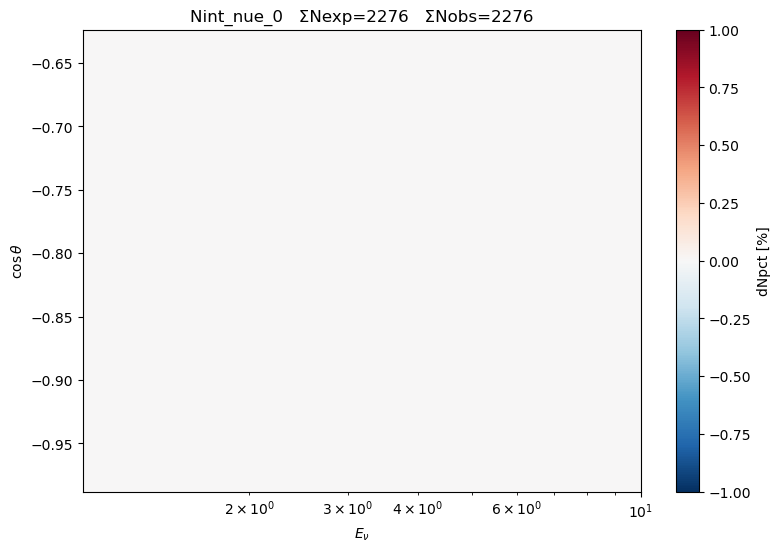

,cth,Enu,Nexp,Nobs,dNpct
0,-0.984455,1.09,1.02199,1.02199,0
1,-0.984455,1.27,9.23229,9.23229,0
2,-0.984455,1.45,2.92134,2.92134,0
3,-0.984455,1.63,3.57979,3.57979,0
4,-0.984455,1.81,5.49887,5.49887,0


In [17]:
plot_map(next(iter(FILES)))
plt.show()
load(next(iter(FILES))).head()

## Interactive explorer (needs `ipywidgets`)

In [ ]:
import ipywidgets as w
GLOBAL = {c: global_vlim(c) for c in ["dNpct", "Nobs", "Nexp"]}

def _view(idx, zcol, logx, annotate, same_scale):
    plot_map(idx, zcol=zcol, logx=logx,
             annotate=None if annotate == "none" else annotate,
             vlim=GLOBAL[zcol] if same_scale else None)
    plt.show()

w.interact(_view,
    idx=w.SelectionSlider(options=list(FILES), description="file #", continuous_update=False),
    zcol=w.Dropdown(options=["dNpct", "Nobs", "Nexp"], value="dNpct", description="color"),
    logx=w.Checkbox(value=True, description="log E_nu"),
    annotate=w.Dropdown(options=["none", "Nobs", "Nexp", "dNpct"], value="none", description="cell text"),
    same_scale=w.Checkbox(value=False, description="same scale all files"));

interactive(children=(SelectionSlider(continuous_update=False, description='file #', options=(0, 1, 2, 3, 4, 5…

## Summary of all files

In [ ]:
rows = []
for i in FILES:
    d = load(i)
    te, to = d.Nexp.sum(), d.Nobs.sum()
    rows.append(dict(file=i, n_bins=len(d), Nexp=te, Nobs=to,
                     dN_total_pct=100 * (to - te) / te if te else np.nan,
                     dNpct_min=d.dNpct.min(), dNpct_max=d.dNpct.max()))
summary = pd.DataFrame(rows).set_index("file")
summary

## Save a PNG of every file (common color scale)

In [ ]:
vl = global_vlim("dNpct")
for i in FILES:
    fig, ax = plot_map(i, zcol="dNpct", vlim=vl, save=True)
    plt.close(fig)
print("Saved plots to", PLOT_DIR)